# 3. Cuadrado con un pozo: ¿hace falta el sumidero $W_-$ en el transporte?

**Pregunta.** El simulador tenía en la ecuación de transporte un término de sumidero en el pozo,
$W_-=\chi(Q)\,g_\varepsilon\,C$, «para que el agua bombeada se lleve el contaminante». Desde la decisión 1
(28-oct-2026) está anulado (`factor_sumidero_C = 0`). Aquí se revisa a fondo si esa decisión es correcta:

1. **Teoría (§1–2):** qué ecuación resuelve cada backend y qué pasa con el término al pasar de la forma conservativa a la
   no conservativa.
2. **Modelo mínimo (§3–7):** cuadrado de 600 m con un pozo central, volúmenes finitos escritos aquí, tres
   formulaciones del transporte con *el mismo* flujo. Cuatro experimentos: C uniforme, limpieza, pluma y barrido
   en $Q$ y $D$. En todos se mide **cómo y cuánto contaminante se escapa por el pozo** con y sin el término.
3. **Simulador (§8):** las corridas reales con y sin el término: BFR en el cuadrado (grupo Z) y FEniCS en el dominio
   real (grupo S).

### Veredicto (detalle en §9)

| | sin $W_-$ (forma NC correcta) | con $W_-$ |
|---|---|---|
| ¿sale el contaminante por el pozo? | **sí**, por el término advectivo: la forma NC ya contiene la extracción | sí, *la misma* masa total |
| C uniforme ($C\equiv C_0$, solución exacta) | se conserva exactamente | agujero en el pozo |
| C del agua extraída (lo que mide $J$) | correcta | 2× menor ($\kappa=Q$) o ~100–300× menor (implementado) |
| con poco bombeo y dispersión | extrae $\approx Q\,C$ | **extrae contaminante que el pozo no puede sacar** (sumidero fantasma) |

**El término no hace falta y además es incorrecto** en la forma no conservativa que usan los dos backends.

In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
import rutas
from cuadrado_nucleo import Cuadrado, DIA
import simulador as S

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
COL = {"cons": "k", "nc": "tab:blue", "Wq": "tab:orange", "W1": "tab:red", "fd": "tab:cyan", "fd1": "tab:pink"}
NOM = {"cons": "conservativa (referencia)", "nc": "NC sin $W_-$", "Wq": "NC + $W_-$, $\\kappa=Q$",
       "W1": "NC + $W_-$ implementado ($\\kappa=1$)", "fd": "NC-FD sin $W_-$", "fd1": "NC-FD + $W_-$ ($\\kappa=1$)"}
CORTO = {"nc": "sin $W_-$", "W1": "con $W_-$ ($\\kappa=1$)"}
FORMAS = {"cons": ("cons", 0, None), "nc": ("nc_fv", 0, None), "Wq": ("nc_fv", 1, None),
          "W1": ("nc_fv", 1, 1.0), "fd": ("nc_fd", 0, None), "fd1": ("nc_fd", 1, 1.0)}

## 1. El término en el código

Los dos backends resuelven el transporte en **forma no conservativa** (NC), con $\mathbf q=-K\nabla h$ el flujo de
Darcy (no la velocidad de poro):
$$
\phi R\,\partial_t C+\mathbf q\cdot\nabla C-\nabla\cdot(D\nabla C)+\lambda\phi R\,C=f\;-\;f_W\,\chi(Q)\,g_\varepsilon(\mathbf x-\mathbf x_p)\,C ,
$$
y el flujo es $S_s\,\partial_t h-\nabla\cdot(K\nabla h)=-Q\,\delta_p$ (el pozo **sí** está en la ecuación del flujo).

| dónde | qué hace |
|---|---|
| `fenicsx/forward.py:353` | `+ f_W * theta_C * inner(delta_C * C, z_t) * dx`, con `delta_C` = $\chi(Q)\,g_\varepsilon$ (`:575`) |
| `funtions/operators.py:475` | `coef_identity -= w * sig * p.factor_sumidero_C * gauss_p` |
| `preprocessing/preprocess.py:73` | `gauss_p = gaussian_2d(nodes, pozo, 1, epsilon_pozo)`: amplitud 1, $\int g_\varepsilon=1$ |
| `funtions/utils.py:165` | $\chi_\epsilon(Q)=\tfrac12(1+\tanh(Q/10^{-6}))$: compuerta 0/1 suave |

**Primera observación (revisión del código):** el término implementado **no lleva el caudal**. Es
$\chi(Q)\,g_\varepsilon C$ con $\chi\in[0,1]$ adimensional, así que equivale a un pozo que extrae
$\kappa=1$ (en las unidades de $Q$) de agua **sea cual sea $Q$**: con $Q_{std}=0.3$ es 3.3× el caudal real; con el
$Q=0.01$ del cuadrado, 100×; y con $Q=10^{-5}$ (pozo casi apagado, $\chi\approx1$) sigue entero. En BFR la compuerta
es aún más gruesa: se activa si la lista `Qout` no está vacía. Abajo escribimos el término en general como
$\kappa\,g_\varepsilon C$ y probamos $\kappa=Q$ (la versión «física» del término) y $\kappa=1$ (la implementada).

## 2. Teoría: la extracción ya está en la forma no conservativa

**Balance de soluto (forma conservativa).** El agua bombeada sale con la concentración local, así que
$$
\partial_t(\phi C)+\nabla\cdot(\mathbf qC)-\nabla\cdot(D\nabla C)=f-Q\,\delta_p\,C .\tag{C}
$$
**Balance de agua.** $\ \partial_t\phi+\nabla\cdot\mathbf q=-Q\,\delta_p$ (en el modelo, $\partial_t\phi=S_s\partial_t h$).

**Paso a la forma NC.** Desarrollando $\partial_t(\phi C)=\phi\partial_tC+C\partial_t\phi$ y
$\nabla\cdot(\mathbf qC)=\mathbf q\cdot\nabla C+C\,\nabla\cdot\mathbf q$:
$$
\phi\partial_tC+\mathbf q\cdot\nabla C-\nabla\cdot(D\nabla C)+C\underbrace{\big(\partial_t\phi+\nabla\cdot\mathbf q\big)}_{=-Q\delta_p}=f-Q\delta_pC
\quad\Longrightarrow\quad
\boxed{\ \phi\partial_tC+\mathbf q\cdot\nabla C-\nabla\cdot(D\nabla C)=f\ }\tag{NC}
$$
El sumidero $-Q\delta_pC$ **se cancela exactamente** con el término $C\,\nabla\cdot\mathbf q$ que aparece al
desarrollar la divergencia. En la forma NC el pozo actúa a través de $\mathbf q$: las líneas de corriente convergen al
pozo y el soluto que llega se va con el agua. No hace falta ningún término extra.

**Consecuencias que se pueden comprobar:**

1. **C uniforme.** Si $C\equiv C_0$ y el agua que entra por el borde trae $C_0$, (C) y (NC) dan $C\equiv C_0$ para todo
   $t$ (el pozo saca $QC_0$ y entra lo mismo). Con $W_-$, (NC) da $\phi\partial_tC=-\kappa g_\varepsilon C\ne0$:
   **agujero** en el pozo. Es la prueba más limpia.
2. **NC + $W_-$ = (C) con un sumidero de más.** Sumar $\kappa g_\varepsilon C$ a (NC) equivale a resolver (C) con
   $-(Q\delta_p+\kappa g_\varepsilon)C$: con $\kappa=Q$ se cuenta **dos veces** la extracción.
3. **La masa total que sale casi no cambia.** Fuera de la zona del pozo ($r\gtrsim\varepsilon$) las dos ecuaciones
   son idénticas, así que la masa que *llega* a esa zona por advección es la misma ($\approx Q\,C$ aguas arriba): con o
   sin $W_-$ esa masa desaparece. Lo único que cambia es la concentración **dentro** de la zona del pozo. Modelo de
   celda bien mezclada que recibe $Q\,C_{in}$: $C_w=C_{in}\,Q/(Q+\kappa)$ (½ con $\kappa=Q$, $\approx Q$ con $\kappa=1$).
4. **Lo que sí cambia es lo que mide el funcional.** $J_m$ observa la C extraída
   ($\int g_\varepsilon C$): con $W_-$ esa cantidad es artificialmente baja, y su derivada respecto a $Q$ también.
5. **Excepción:** si la difusión alimenta el agujero (dispersión grande, $Q$ pequeño), $W_-$ con $\kappa=1$ saca
   masa que el pozo no podría extraer. Se mide en §7.

**¿De dónde salió $W_-$?** En los peldaños 2 y 2c (`2_benchmarks_libro`) el pozo se modela como un sumidero
$u_i\psi_i\,y$ en la ecuación de transporte, **porque allí la velocidad es la de Graetz y no siente el pozo**
($\nabla\cdot\mathbf b=0$). Ese modelo es correcto en ese problema. En el acuífero el pozo cambia el flujo
($\nabla\cdot\mathbf q=-Q\delta_p$) y entonces el sumidero ya está dentro de $\mathbf q\cdot\nabla C$: ponerlo además
es contarlo dos veces.

**Nota sobre el almacenamiento.** La cancelación usa $\partial_t\phi=S_s\partial_th$. El simulador toma $\phi$
constante en el transporte, pero $S_s\partial_th\ne0$ en el flujo (y con $S_s=\phi$, el valor por defecto, es
grande). La forma NC sigue siendo la correcta. Lo que deja de conservarse es la masa medida con $\phi$ fijo: aparece un
término $-\int C\,S_s\partial_th$ que, con abatimiento ($\partial_th<0$), **crea** masa aparente. Es el «la masa sube
sin fuente con el pozo» del grupo W. Es un problema distinto de $W_-$ y no se arregla con $W_-$.

## 3. Modelo mínimo: cuadrado con pozo central (volúmenes finitos)

$\Omega=(-300,300)^2$ m, celdas de $\approx10$ m ($61\times61$), pozo en el centro con los kernels del simulador:
$\delta_p$ = Wendland C2 de radio $r_{pozo}=20$ m (flujo) y $g_\varepsilon$ gaussiana con $\varepsilon=r_{pozo}/3$
(término $W_-$ y C captada). $K=10^{-3}$, $\phi=0.1$, $Q=0.01$ (como el grupo Z), $D=10^{-5}$ salvo en §7.

**Flujo:** estacionario, $h=300$ en el borde (lo que la condición «libre» produce en el cuadrado, ver grupo Z), con
continuidad discreta exacta: la salida neta de cada celda es $-Q\,w_i$.

**Transporte:** Euler implícito, $\Delta t=0.25$ d, upwind. Tres discretizaciones con el mismo flujo:

| clave | ecuación | discretización |
|---|---|---|
| `cons` | (C) | VF con caudales de cara: la **referencia física** (conserva masa por construcción) |
| `nc` | (NC) $+\,f_W\kappa g_\varepsilon C$ | VF de (C) menos $C_i\times$(continuidad discreta): $\sum_{f\,\text{entrante}}F_f(C_{vec}-C_i)$ |
| `fd` | (NC) $+\,f_W\kappa g_\varepsilon C$ | diferencias por nodo con $\mathbf q$ en el nodo, **sin** caudales de cara (como RBF-FD/FEM del simulador) |

`nc` con $f_W=0$ es *algebraicamente* igual a `cons`. `fd` comprueba que la conclusión no depende de esa
identidad discreta.

continuidad discreta: max|Σ_f F_f + Q w_i|/Q = 1.1e-13


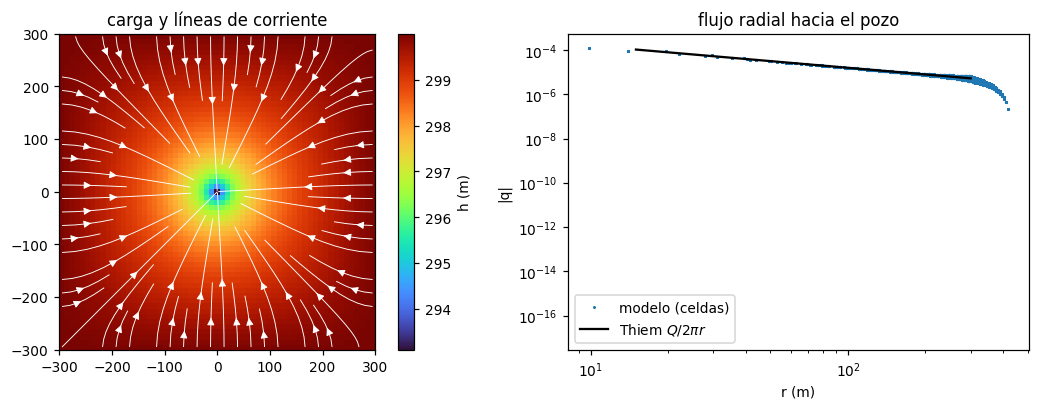

In [2]:
m = Cuadrado()
print(f"continuidad discreta: max|Σ_f F_f + Q w_i|/Q = {m.err_continuidad:.1e}")
r = np.hypot(m.X, m.Z).ravel()
q = np.hypot(m.qx, m.qz)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
im = ax[0].imshow(m.h.reshape(m.n, m.n).T, origin="lower", extent=(-300, 300, -300, 300), cmap="turbo")
ax[0].streamplot(m.X[:, 0], m.Z[0], m.qx.reshape(m.n, m.n).T, m.qz.reshape(m.n, m.n).T, color="w", density=0.8, linewidth=0.6)
plt.colorbar(im, ax=ax[0], label="h (m)"); ax[0].set_title("carga y líneas de corriente"); ax[0].set_aspect("equal")
rr = np.linspace(15, 300, 100)
ax[1].loglog(r, q, ".", ms=2, label="modelo (celdas)")
ax[1].loglog(rr, m.Q / (2 * np.pi * rr), "k-", label="Thiem $Q/2\\pi r$")
ax[1].set(xlabel="r (m)", ylabel="|q|", title="flujo radial hacia el pozo"); ax[1].legend()
plt.tight_layout(); plt.show()

Lejos del pozo $|\mathbf q|$ sigue a Thiem, salvo en las esquinas, donde el borde cuadrado lo hace más lento.
Tiempo de viaje desde $r$: $\pi r^2\phi/Q$, unos 21 d desde $r=240$ m.

## 4. Experimento A: C uniforme (la prueba de consistencia)

$C(0)=1$ en todo el cuadrado, el agua que entra por el borde trae $C=1$ y $T=30$ d. **Solución exacta:** $C\equiv1$.

formulación                               masa(T)/m0  C pozo (δ) C captada (g)     min C
conservativa (referencia)                   1.000000           1             1  1.00e+00
NC sin $W_-$                                1.000000           1             1  1.00e+00
NC + $W_-$, $\kappa=Q$                      0.999013      0.4656        0.5344  3.43e-01
NC + $W_-$ implementado ($\kappa=1$)        0.995122    0.001483      0.009985  2.21e-05
NC-FD sin $W_-$                             1.000000           1             1  1.00e+00
NC-FD + $W_-$ ($\kappa=1$)                  0.995142    0.001492       0.01024  1.89e-07


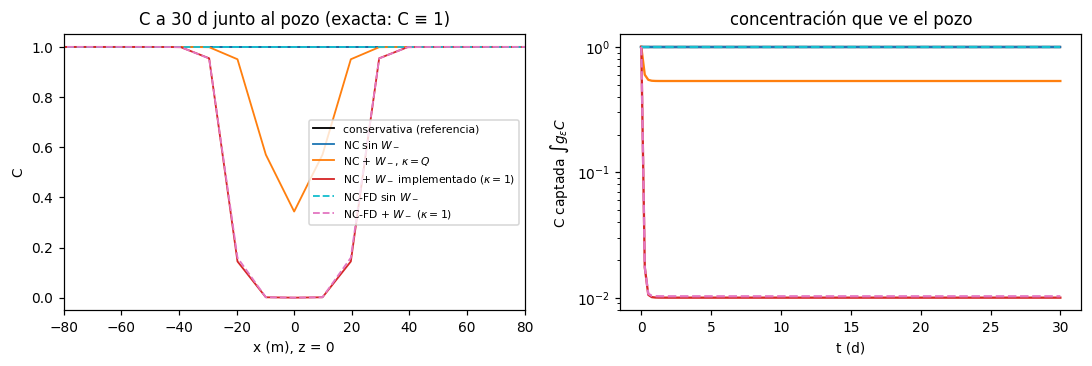

In [3]:
def correr(m, clave, C0, C_b=0.0, T=30, dt=0.25):
    forma, fW, k = FORMAS[clave]
    return m.correr(forma, C0, C_b=C_b, T_fin=T * DIA, dt=dt * DIA, f_W=fW, kappa=k)

A = {k: correr(m, k, np.ones(m.N), C_b=1.0) for k in FORMAS}
print(f"{'formulación':40s} {'masa(T)/m0':>11s} {'C pozo (δ)':>11s} {'C captada (g)':>13s} {'min C':>9s}")
for k, o in A.items():
    print(f"{NOM[k]:40s} {o['masa'][-1] / o['masa'][0]:11.6f} {o['c_pozo'][-1]:11.4g} {o['captada'][-1]:13.4g} {o['C'][-1].min():9.2e}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
j0 = m.n // 2
x = m.X[:, 0]
for k, o in A.items():
    ax[0].plot(x, o["C"][-1].reshape(m.n, m.n)[:, j0], color=COL[k], label=NOM[k], lw=1.2,
               ls="--" if k.startswith("fd") else "-")
    ax[1].semilogy(o["t"], np.maximum(o["captada"], 1e-6), color=COL[k], ls="--" if k.startswith("fd") else "-")
ax[0].set(xlim=(-80, 80), xlabel="x (m), z = 0", ylabel="C", title="C a 30 d junto al pozo (exacta: C ≡ 1)")
ax[1].set(xlabel="t (d)", ylabel="C captada $\\int g_\\varepsilon C$", title="concentración que ve el pozo")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Sin $W_-$ la C uniforme se conserva a precisión de máquina** en las tres discretizaciones (incluida `fd`, que no
usa la continuidad discreta). **Con $W_-$ aparece un agujero** que no corresponde a nada físico: con $\kappa=Q$ el
pozo ve la mitad ($Q/(Q+\kappa)=\tfrac12$, consecuencia 3) y con el término implementado ($\kappa=1$) ve
$\approx10^{-3}$. La masa total apenas cambia (0.1–0.5 %): el agujero ocupa sólo la zona del kernel.

## 5. Experimento B: limpieza del cuadrado (cómo se escapa el contaminante)

$C(0)=1$ salvo una franja limpia de 60 m junto al borde (como el grupo Z), y el agua que entra es limpia
($C_b=0$). Sin fuente, el soluto sólo puede salir por el pozo (en el borde sólo entra agua).

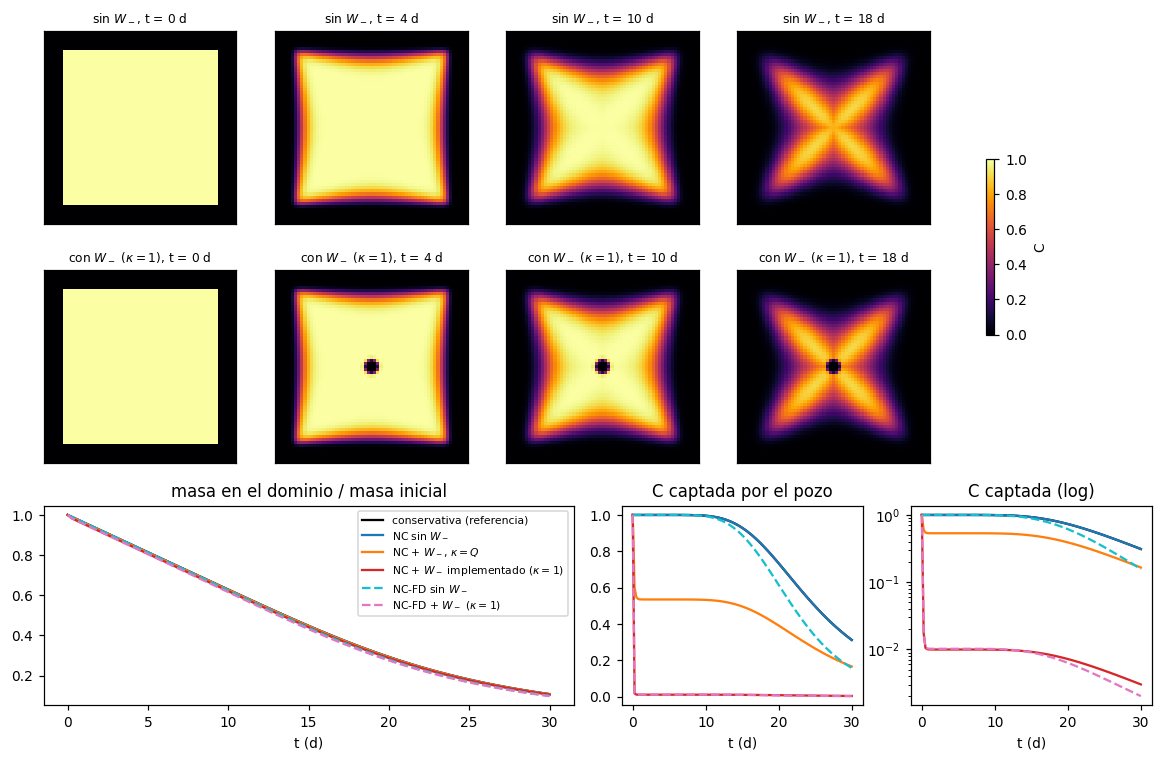

formulación                               perdida a 10 d   a 30 d  Q∫C_pozo dt / m0  (Q+κ)∫ ... / m0
conservativa (referencia)                         0.3718   0.8924            0.8924           0.8924
NC sin $W_-$                                      0.3718   0.8924            0.8924           0.8924
NC + $W_-$, $\kappa=Q$                            0.3733   0.8929            0.4153           0.8929
NC + $W_-$ implementado ($\kappa=1$)              0.3793   0.8948            0.0013           0.8948
NC-FD sin $W_-$                                   0.3769   0.9009            0.8229           0.8229
NC-FD + $W_-$ ($\kappa=1$)                        0.3844   0.9024            0.0012           0.8531


In [4]:
limpio = ((np.abs(m.X) < 240) & (np.abs(m.Z) < 240)).ravel() * 1.0
B = {k: correr(m, k, limpio, T=30) for k in ("cons", "nc", "Wq", "W1", "fd", "fd1")}

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(3, 4, height_ratios=[1, 1, 1])
dias = (0, 4, 10, 18)
for fila, k in enumerate(("nc", "W1")):
    o = B[k]
    for c, d in enumerate(dias):
        a = fig.add_subplot(gs[fila, c])
        it = int(round(d / 0.25))
        im = a.imshow(o["C"][it].reshape(m.n, m.n).T, origin="lower", extent=(-300, 300, -300, 300), vmin=0, vmax=1, cmap="inferno")
        a.set_title(f"{CORTO[k]}, t = {d} d", fontsize=8); a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=fig.axes, shrink=0.4, location="right", label="C")
a1, a2, a3 = fig.add_subplot(gs[2, 0:2]), fig.add_subplot(gs[2, 2]), fig.add_subplot(gs[2, 3])
for k, o in B.items():
    ls = "--" if k.startswith("fd") else "-"
    a1.plot(o["t"], o["masa"] / o["masa"][0], color=COL[k], ls=ls, label=NOM[k])
    a2.plot(o["t"], o["captada"], color=COL[k], ls=ls)
    a3.semilogy(o["t"], np.maximum(o["captada"], 1e-5), color=COL[k], ls=ls)
a1.set(xlabel="t (d)", title="masa en el dominio / masa inicial"); a1.legend(fontsize=7)
a2.set(xlabel="t (d)", title="C captada por el pozo"); a3.set(xlabel="t (d)", title="C captada (log)")
plt.show()

print(f"{'formulación':40s} {'perdida a 10 d':>15s} {'a 30 d':>8s} {'Q∫C_pozo dt / m0':>17s} {'(Q+κ)∫ ... / m0':>16s}")
for k, o in B.items():
    m0 = o["masa"][0]
    k_ = FORMAS[k][2]
    kap = 0.0 if FORMAS[k][1] == 0 else (m.Q if k_ is None else k_)
    sale = m.Q * np.sum(o["c_pozo"][1:]) * o["dt"] / m0
    sale_W = kap * np.sum(o["captada"][1:]) * o["dt"] / m0
    print(f"{NOM[k]:40s} {1 - o['masa'][40] / m0:15.4f} {1 - o['masa'][-1] / m0:8.4f} {sale:17.4f} {sale + sale_W:16.4f}")

**Cómo se escapa el contaminante.** En la fila de arriba (NC sin $W_-$), el frente limpio avanza desde el borde
hacia el pozo y el soluto se va por el pozo. En la de abajo (con el término implementado) pasa **lo mismo**: la masa
en el dominio baja con la misma curva (diferencia < 1 % de $m_0$). La única diferencia visible es el punto negro
en el centro, el agujero.

La tabla cierra el balance: en `cons`/`nc`, lo que sale por el pozo, $Q\int C_{pozo}\,dt$, es exactamente la masa
perdida. Con $W_-$ la masa se va por dos vías a la vez, $Q C_{pozo}+\kappa\,C_{capt}$, y suman lo mismo que antes.
Con $W_-$, quien lea la C extraída como $Q\,C_{pozo}$ (lo que hace $J$) **subestima la masa extraída** 2× ($\kappa=Q$) o
~$10^2$–$10^3$× ($\kappa=1$). `fd` no conserva masa exactamente: su $Q\int C_{pozo}$ cierra al ~91 %, aunque la curva
de masa sea la misma. Pasa lo mismo con RBF-FD y FEM, que discretizan la forma NC; se ve en §8.

## 6. Experimento C: una pluma que llega al pozo (lo que ve el bombeo)

Pluma gaussiana ($\sigma=40$ m) centrada a 160 m del pozo, agua limpia por el borde y 30 d. La curva de llegada
(BTC) al pozo es lo que observa $J_m$.

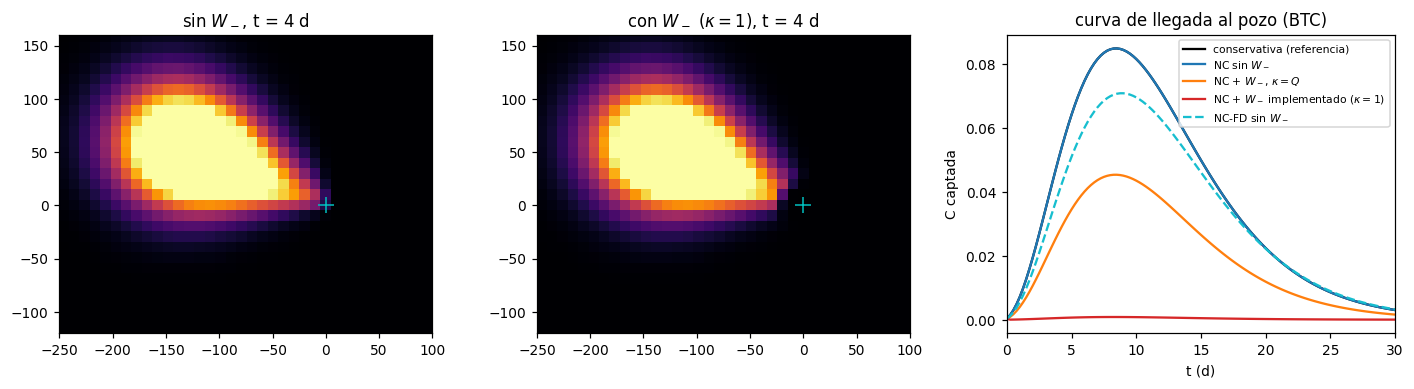

conservativa (referencia)                pico 0.0848 en t =  8.50 d   masa a 30 d 1.16e-02
NC sin $W_-$                             pico 0.0848 en t =  8.50 d   masa a 30 d 1.16e-02
NC + $W_-$, $\kappa=Q$                   pico 0.0453 en t =  8.50 d   masa a 30 d 1.15e-02
NC + $W_-$ implementado ($\kappa=1$)     pico 0.0008 en t =  8.25 d   masa a 30 d 1.11e-02
NC-FD sin $W_-$                          pico 0.0708 en t =  9.00 d   masa a 30 d 1.07e-02


In [5]:
pluma = np.exp(-((m.X.ravel() + 150) ** 2 + (m.Z.ravel() - 60) ** 2) / (2 * 40 ** 2))
Cp = {k: correr(m, k, pluma, T=30) for k in ("cons", "nc", "Wq", "W1", "fd")}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for i, (k, d) in enumerate((("nc", 4), ("W1", 4))):
    it = int(round(d / 0.25))
    ax[i].imshow(Cp[k]["C"][it].reshape(m.n, m.n).T, origin="lower", extent=(-300, 300, -300, 300), vmin=0, vmax=0.4, cmap="inferno")
    ax[i].plot(0, 0, "c+", ms=10); ax[i].set_title(f"{CORTO[k]}, t = {d} d"); ax[i].set_xlim(-250, 100); ax[i].set_ylim(-120, 160)
for k, o in Cp.items():
    ax[2].plot(o["t"], o["captada"], color=COL[k], ls="--" if k == "fd" else "-", label=NOM[k])
ax[2].set(xlabel="t (d)", ylabel="C captada", title="curva de llegada al pozo (BTC)", xlim=(0, 30)); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
for k, o in Cp.items():
    i = o["captada"].argmax()
    print(f"{NOM[k]:40s} pico {o['captada'][i]:.4f} en t = {o['t'][i]:5.2f} d   masa a 30 d {o['masa'][-1] / o['masa'][0]:.2e}")

La pluma llega al pozo **en el mismo instante** con o sin el término y se extrae entera en los dos casos. El pico de la
BTC con $W_-$ es la mitad ($\kappa=Q$) o desaparece ($\kappa=1$). Un optimizador que minimice la C extraída con el
término activo vería una pluma de 2 a 100 veces más débil que la que de verdad sale por el pozo.

## 7. Experimento D: barrido en caudal y dispersión (el sumidero fantasma)

Limpieza de 30 d con $Q\in[10^{-4},10^{-1}]$ y dos coeficientes de dispersión. Se mide la fracción de masa que se ha
ido del dominio.

(5 s)
     D       Q |             masa perdida a 30 d              |           C captada a 30 d          
               |     cons       nc    W κ=Q    W κ=1  κ=1/cons |     cons    W κ=Q    W κ=1
 1e-05   1e-04 |   0.0112   0.0112   0.0139   0.0321      2.88 |        1    0.582 0.000152
 1e-05   1e-03 |   0.1116   0.1116   0.1133   0.1231      1.10 |        1    0.533    0.001
 1e-05   1e-02 |   0.8883   0.8883   0.8888   0.8908      1.00 |    0.321     0.17  0.00312
 1e-05   1e-01 |   1.0000   1.0000   1.0000   1.0000      1.00 | 4.01e-16 2.13e-16 3.71e-17
 1e-03   1e-04 |   0.0091   0.0091   0.0175   0.2593     28.35 |    0.678    0.644  0.00141
 1e-03   1e-03 |   0.0892   0.0892   0.1306   0.2969      3.33 |     0.64     0.45  0.00162
 1e-03   1e-02 |   0.6564   0.6564   0.6629   0.6801      1.04 |    0.293    0.151  0.00282
 1e-03   1e-01 |   1.0000   1.0000   1.0000   1.0000      1.00 | 3.56e-06 1.89e-06 3.35e-07


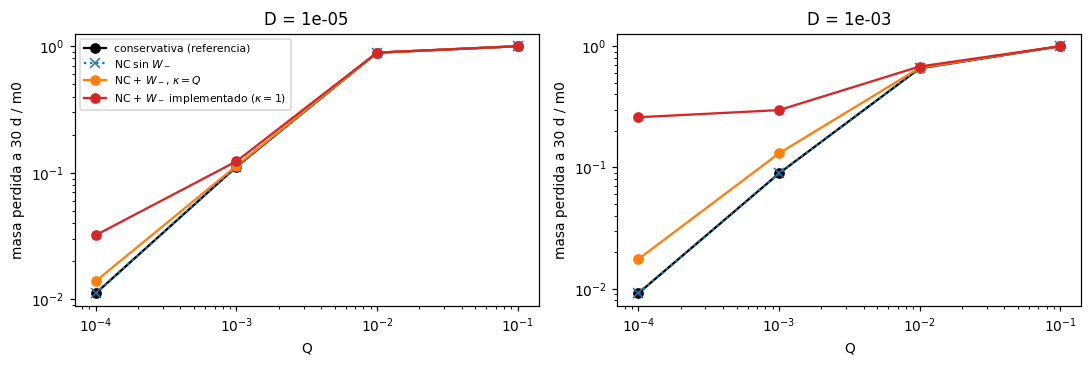

In [6]:
filas = []
t0 = time.time()
for D in (1e-5, 1e-3):
    for Qv in (1e-4, 1e-3, 1e-2, 1e-1):
        mm = Cuadrado(Q=Qv, D=D)
        lim = ((np.abs(mm.X) < 240) & (np.abs(mm.Z) < 240)).ravel() * 1.0
        res = {k: correr(mm, k, lim, T=30, dt=0.5) for k in ("cons", "nc", "Wq", "W1")}
        filas.append((D, Qv, {k: 1 - o["masa"][-1] / o["masa"][0] for k, o in res.items()},
                      {k: o["captada"][-1] for k, o in res.items()}))
print(f"({time.time() - t0:.0f} s)")
print(f"{'D':>6s} {'Q':>7s} | {'masa perdida a 30 d':^44s} | {'C captada a 30 d':^36s}")
print(f"{'':15s}| {'cons':>8s} {'nc':>8s} {'W κ=Q':>8s} {'W κ=1':>8s} {'κ=1/cons':>9s} | {'cons':>8s} {'W κ=Q':>8s} {'W κ=1':>8s}")
for D, Qv, p, c in filas:
    print(f"{D:6.0e} {Qv:7.0e} | {p['cons']:8.4f} {p['nc']:8.4f} {p['Wq']:8.4f} {p['W1']:8.4f} {p['W1'] / p['cons']:9.2f} |"
          f" {c['cons']:8.3g} {c['Wq']:8.3g} {c['W1']:8.3g}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for i, D in enumerate((1e-5, 1e-3)):
    Qs = [f[1] for f in filas if f[0] == D]
    for k in ("cons", "nc", "Wq", "W1"):
        ax[i].loglog(Qs, [f[2][k] for f in filas if f[0] == D], "o-" if k != "nc" else "x:", color=COL[k], label=NOM[k])
    ax[i].set(xlabel="Q", ylabel="masa perdida a 30 d / m0", title=f"D = {D:.0e}")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

* Con dispersión pequeña y $Q\ge10^{-3}$, la masa perdida es **la misma** con y sin el término (consecuencia 3): el
  término no saca más soluto, sólo cambia la C del pozo. Con $Q=10^{-4}$ el término implementado ya saca 2.9× más
  que el pozo físico.
* Con dispersión grande y poco caudal, el término implementado ($\kappa=1$) **saca contaminante que el pozo no puede
  extraer**. Con $Q=10^{-4}$ el pozo físico saca ~1 % en 30 d y el término, ~26 %: la difusión rellena el agujero y el
  término se lo lleva. Para la optimización esto es grave, porque recompensa encender el pozo con un caudal
  mínimo (la compuerta $\chi$ vale 1 desde $Q\sim10^{-5}$).
* La forma NC sin el término reproduce la referencia conservativa en todos los casos.

## 8. Lo mismo en el simulador

### 8.1 BFR en el cuadrado (grupo Z, rama `exp/sumidero-W`)

Cuadrado de 600 m, pozo central, condición libre en todo el borde, $Q=0.01$, $S_s=10^{-5}$, $\phi=0.1$, anisotropía
$\alpha=2$ ($|\mathbf q|_x\approx4.8\,|\mathbf q|_z$), $C_0$ salvo una franja limpia de 60 m, 90 d. Z0 sin
$W_-$ y Z1 con el término implementado (factor 1).

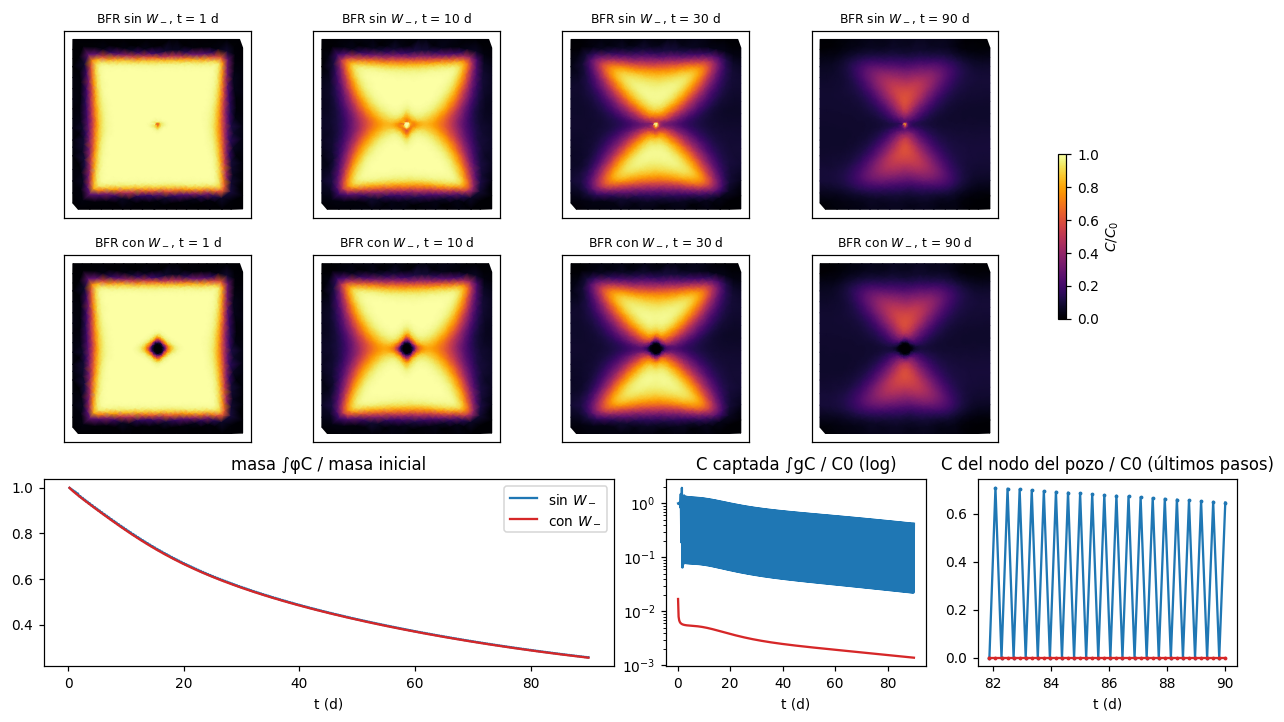

sin W-: masa a 10/30/60/90 d = 0.8183, 0.5649, 0.3713, 0.2563   C captada mediana (2.ª mitad) = 0.2286
con W-: masa a 10/30/60/90 d = 0.8128, 0.5612, 0.3686, 0.2543   C captada mediana (2.ª mitad) = 0.0018


In [7]:
Z = {"sin": S.cargar_Z("Z0_sin_sumidero"), "con": S.cargar_Z("Z1_con_sumidero")}
fig = plt.figure(figsize=(14, 7.5))
gs = fig.add_gridspec(3, 4)
for fila, k in enumerate(("sin", "con")):
    z = Z[k]
    for c, d in enumerate((1, 10, 30, 90)):
        a = fig.add_subplot(gs[fila, c])
        it = int(np.argmin(np.abs(z["t"] - d)))
        tp = a.tripcolor(z["tri"], z["C"][it], vmin=0, vmax=1, cmap="inferno", shading="gouraud")
        a.set_title(f"BFR {k} $W_-$, t = {z['t'][it]:.0f} d", fontsize=8); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
fig.colorbar(tp, ax=fig.axes, shrink=0.4, location="right", label="$C/C_0$")
a1, a2, a3 = fig.add_subplot(gs[2, 0:2]), fig.add_subplot(gs[2, 2]), fig.add_subplot(gs[2, 3])
for k, col in (("sin", "tab:blue"), ("con", "tab:red")):
    z = Z[k]
    a1.plot(z["t"], z["masa"], color=col, label=f"{k} $W_-$")
    a2.semilogy(z["t"], np.maximum(z["captada"], 1e-5), color=col)
    a3.plot(z["t"][-40:], z["c_nodo_pozo"][-40:], ".-", color=col, ms=3)
a1.set(xlabel="t (d)", title="masa ∫φC / masa inicial"); a1.legend()
a2.set(xlabel="t (d)", title="C captada ∫gC / C0 (log)"); a3.set(xlabel="t (d)", title="C del nodo del pozo / C0 (últimos pasos)")
plt.show()
for k, z in Z.items():
    print(f"{k} W-: masa a 10/30/60/90 d = " + ", ".join(f"{z['masa'][np.argmin(np.abs(z['t'] - d))]:.4f}" for d in (10, 30, 60, 90))
          + f"   C captada mediana (2.ª mitad) = {np.median(z['captada'][len(z['t']) // 2:]):.4f}")

El simulador hace lo mismo que el modelo mínimo:
* **la masa baja igual con y sin el término** (25.6 % y 25.4 % de $m_0$ a 90 d): **en los dos casos el contaminante
  se escapa por el pozo**. Aquí no se limpia del todo en 90 d por la anisotropía: el pozo drena rápido en $x$ y despacio
  en $z$;
* con el término, la C captada cae de 100 a 300 veces (a ≈0.001–0.005 de $C_0$), del orden de $(Q+\kappa)/Q=101$
  que predice la celda bien mezclada;
* sin el término aparece un defecto **de la discretización RBF-FD, no del modelo**: el nodo del pozo alterna
  0 ↔ 0.65 $C_0$ de un paso a otro y la C captada oscila entre ≈0.02 y ≈0.4 $C_0$ (al principio llega a 1.9,
  sobreoscilación). Una oscilación de periodo 2 no la produce Euler implícito ($\theta_C=1$) por sí solo. La
  sospecha es el recorte $C\ge0$ de cada paso junto al esquema centrado en el punto donde convergen las líneas de
  corriente, pero **no está verificado**. El término lo tapaba con el agujero. La masa no se ve afectada. Queda
  pendiente (upwind local en el pozo, kernel de transporte más ancho, o quitar el recorte).

### 8.2 FEniCS en el dominio real: fuente 30 d y 90 d de limpieza (grupo S, S2/S3)

Configuración de referencia ADR ($Q_{std}=0.3$), la fuente se apaga a los 30 d y se sigue hasta 120 d. FEniCS guarda
el balance por paso.

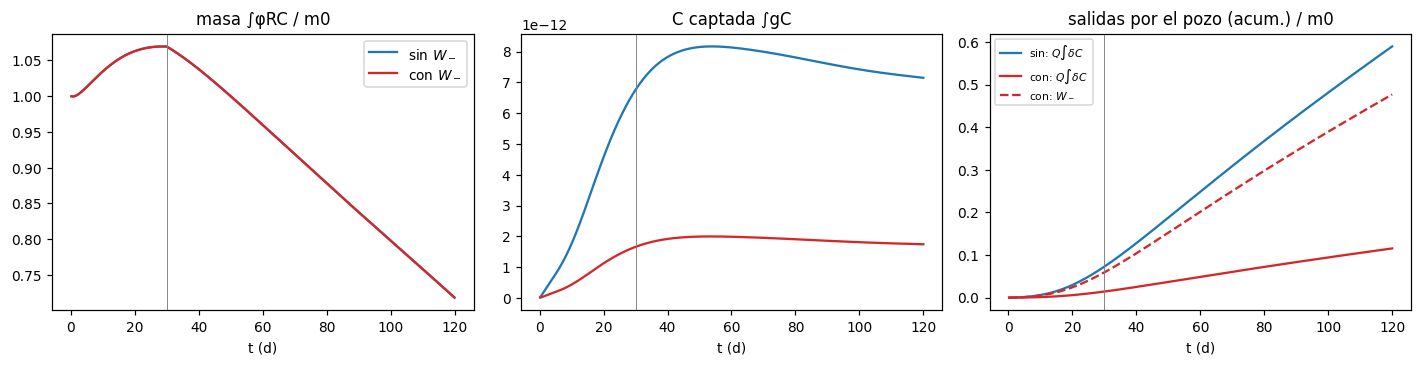

t =  30 d   masa sin/con = 1.06941 / 1.06929   C captada sin/con = 6.760e-12 / 1.658e-12  (×4.1)
t =  60 d   masa sin/con = 0.95991 / 0.95976   C captada sin/con = 8.135e-12 / 1.987e-12  (×4.1)
t = 120 d   masa sin/con = 0.71854 / 0.71840   C captada sin/con = 7.150e-12 / 1.742e-12  (×4.1)

S0/S1 (30 d, BFR y FEniCS):
BFR (RBF-FD)   con W₋   ∫C final/máx = 1.0000   C captada final = 4.0573e-13   máx = 4.0573e-13
BFR (RBF-FD)   sin W₋   ∫C final/máx = 1.0000   C captada final = 3.2095e-12   máx = 3.2095e-12
FEniCS (FEM)   con W₋   ∫C final/máx = 1.0000   C captada final = 1.6643e-12   máx = 1.6643e-12
FEniCS (FEM)   sin W₋   ∫C final/máx = 1.0000   C captada final = 6.7485e-12   máx = 6.7485e-12



In [8]:
Bf = {"sin": S.cargar_balance_fem("S2_limpieza_sin"), "con": S.cargar_balance_fem("S3_limpieza_con")}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for k, col in (("sin", "tab:blue"), ("con", "tab:red")):
    b = Bf[k]
    ax[0].plot(b["t"], b["masa"], color=col, label=f"{k} $W_-$")
    ax[1].plot(b["t"], b["captada"], color=col)
    ax[2].plot(b["t"], b["agua"], color=col, label=f"{k}: $Q\\int\\delta C$")
    if k == "con":
        ax[2].plot(b["t"], b["W"], color=col, ls="--", label="con: $W_-$")
ax[0].set(xlabel="t (d)", title="masa ∫φRC / m0"); ax[0].legend()
ax[1].set(xlabel="t (d)", title="C captada ∫gC"); ax[2].set(xlabel="t (d)", title="salidas por el pozo (acum.) / m0"); ax[2].legend(fontsize=7)
for a in ax: a.axvline(30, color="gray", lw=0.6)
plt.tight_layout(); plt.show()
for d in (30, 60, 120):
    i = [int(np.argmin(np.abs(b["t"] - d))) for b in Bf.values()]
    ms = [b["masa"][j] for b, j in zip(Bf.values(), i)]
    cs = [b["captada"][j] for b, j in zip(Bf.values(), i)]
    print(f"t = {d:3d} d   masa sin/con = {ms[0]:.5f} / {ms[1]:.5f}   C captada sin/con = {cs[0]:.3e} / {cs[1]:.3e}  (×{cs[0] / cs[1]:.1f})")
res = rutas.grupo("S_sumidero") / "resumen.txt"
print("\nS0/S1 (30 d, BFR y FEniCS):\n" + res.read_text() if res.exists() else "")

En el dominio real pasa lo mismo: la masa coincide a 4 cifras con y sin el término a 120 d (0.7185 / 0.7184),
así que la limpieza ocurre igual. La C captada es 4.1× menor con el término ($(Q+\kappa)/Q=(0.3+1)/0.3=4.3$). A 30 d
(S0/S1) la C captada es 8× menor en BFR y 4× en FEM con el término, y $\int C$ coincide a $10^{-4}$.

La curva $Q\int\delta C$ sin el término (≈59 % de $m_0$) es mucho mayor que la masa perdida (≈36 %): las
discretizaciones NC no conservan masa exactamente (como `fd` en §5), y además está la masa aparente que crea el
almacenamiento con $\phi$ fijo (§2, nota). Ninguna de las dos cosas tiene que ver con $W_-$.

## 9. Veredicto e implicaciones

1. **En la forma no conservativa (la de los dos backends) el sumidero $W_-$ no hace falta: el pozo ya extrae el
   contaminante a través de $\mathbf q\cdot\nabla C$** (la cancelación de §2 es exacta). En todos los experimentos,
   sin el término la masa sale por el pozo exactamente como en la forma conservativa de referencia.
2. **Con el término, la masa total que sale casi no cambia**, pero la C del agua extraída se reduce
   $Q/(Q+\kappa)$: 2× si el término llevara $Q$ y 4–300× con el término implementado (sin $Q$). Esa C es justo lo
   que observan $J_m$ y su gradiente.
3. **El término implementado es además dimensionalmente incorrecto** (coeficiente 1 en lugar de $Q$) y con
   dispersión crea un **sumidero fantasma** que limpia el acuífero sin bombear (§7).
4. **Para la tesis:** escribir el transporte en forma NC *sin* $W_-$, o en forma conservativa *con* $-Q\delta_pC$
   (las dos son equivalentes, §2). Nunca la NC con el sumidero. Conviene anotar en el texto que el modelo de
   pozo-reacción de los peldaños del libro sólo vale cuando la velocidad no siente el pozo.
5. **Pendientes que este análisis destapa** (independientes de $W_-$):
   (a) oscilación del nodo del pozo en BFR sin el término (§8.1);
   (b) masa aparente creada por $S_s\partial_th$ con $\phi$ fijo y $S_s=\phi$ (§2);
   (c) las discretizaciones NC no cierran el balance $Q\int\delta C$ con la masa perdida. Para un diagnóstico
   de masa en el simulador, usar la masa del dominio, no la «salida con el agua».